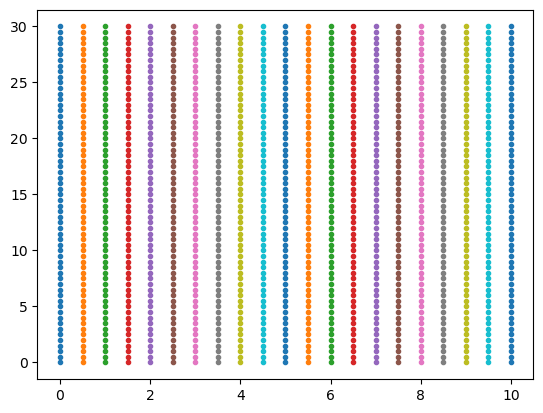

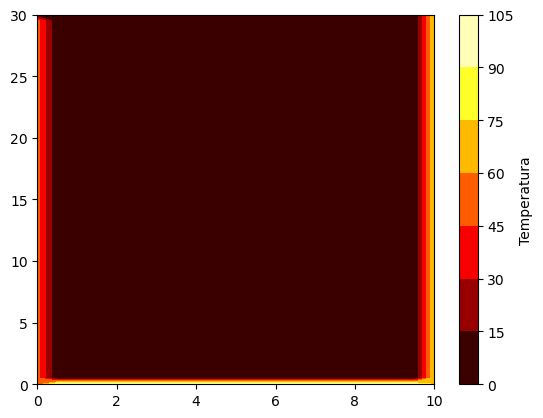

In [76]:
import numpy as np
import matplotlib.pyplot as plt

# "Dibujo de la figura a resolver"
Lx = 10
Ly = 30
# Discretización de x y y

dx = 0.5
dy = 0.5
x = np.arange(0, Lx + dx, dx)
y = np.arange(0, Ly + dy, dy)
nx = len(x)
ny = len(y)

X, Y = np.meshgrid(x, y)

plt.plot(X, Y, '.')
plt.show()
# variable de temperatura
T = np.zeros((ny, nx))

# Condiciones de frontera
T[0, :] = 100  # Frontera superior
T[:,0] = 50    # Frontera izquierda
T[ny-1, :] = 0   # Frontera inferior
T[:, nx-1] = 75   # Frontera derecha

plt.contourf(X, Y, T, cmap='hot')
plt.colorbar(label='Temperatura')

Error aproximado: 1.00%


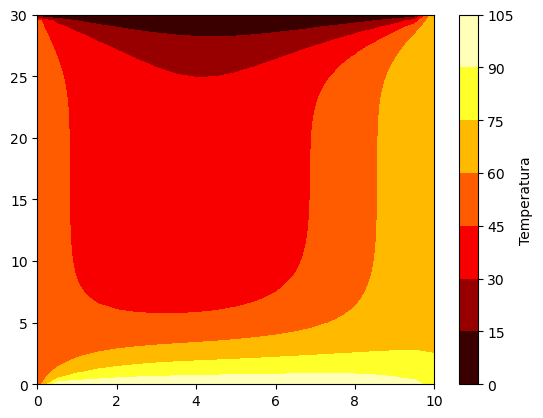

In [77]:
# Cálculo de la temperatura en el interior
while True:
    T_vieja = T.copy()
    for j in range(1, ny-1):
        for i in range(1, nx-1):
            T[j,i] = (T[j,i+1] + T[j,i-1] + T[j+1,i] + T[j-1,i]) / 4
    error_aprox = np.max(np.abs((T[1:ny-1, 1:nx-1] - T_vieja[1:ny-1, 1:nx-1]) / T[1:ny-1, 1:nx-1]))*100
    if error_aprox < 1:
        break
print(f'Error aproximado: {error_aprox:.2f}%')
plt.contourf(X, Y, T, cmap='hot')
plt.colorbar(label='Temperatura')

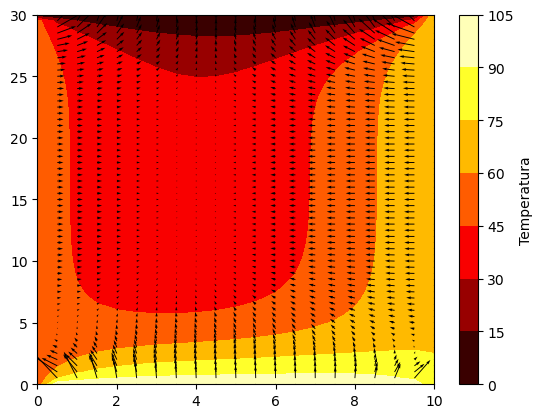

In [78]:
# Cálculo de flujos de calor
dT_dx = np.zeros((ny, nx))
dT_dy = np.zeros((ny, nx))
for j in range(1, ny-1):
    for i in range(1, nx-1):
        dT_dx[j,i] = (T[j,i+1] - T[j,i-1]) / (2*dx)
        dT_dy[j,i] = (T[j+1,i] - T[j-1,i]) / (2*dy)

k = 1  # Conductividad térmica
q_x = -k * dT_dx
q_y = -k * dT_dy
plt.contourf(X, Y, T, cmap='hot')
plt.colorbar(label='Temperatura')
plt.quiver(X, Y, q_x, q_y)
plt.show()


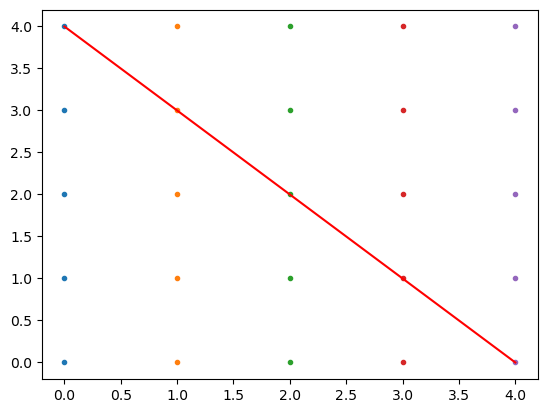

In [ ]:
# Placa triangular
import matplotlib.pyplot as plt
import numpy as np

# Definición de la geometría de la placa triangular
Lx = 4  # Longitud de la base del triángulo
Ly = 4  # Altura del triángulo
# Discretización de x y y
dx = dy = 1

x = np.arange(0, Lx + dx, dx)
y = np.arange(0, Ly + dy, dy)

X, Y = np.meshgrid(x, y)

plt.plot(X, Y, '.')
plt.plot(x,-Ly/Lx*x+Ly, 'r')  # Línea que representa la hipotenusa del triángulo




Error aproximado: nan%


/var/folders/z3/qlt6drrn06gdv5wy2zcfx1xc0000gn/T/ipykernel_3829/2198976964.py:18: RuntimeWarning: invalid value encountered in divide
  error_aprox = np.max(np.abs(T-T_vieja)/T)*100


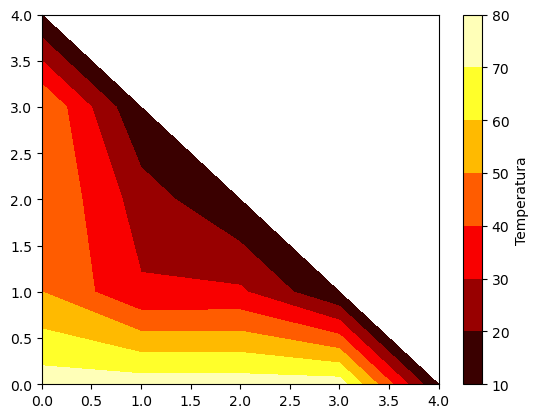

In [90]:
# condiciones de frontera
T = np.zeros((len(y), len(x)))
T[:,0 ] = 50
T[0,:] = 75
for j in range(len(y)):
    for i in range(len(x)):
        if Y[j,i] == -Ly/Lx*X[j,i]+Ly:
            T[j,i] = 10

error_aprox = 100
while error_aprox > 1:
    T_vieja = T.copy()
    for j in range(1, len(y)-1):
        for i in range(1, len(x)-1):
            if Y[j,i] < -Ly/Lx*X[j,i]+Ly:
                T[j,i] = (T[j,i+1] + T[j,i-1] + T[j+1,i] + T[j-1,i]) / 4
    
    error_aprox = np.max(np.abs(T-T_vieja)/T)*100 
    
    print(f'Error aproximado: {error_aprox:.2f}%')

for j in range(len(y)):
    for i in range(len(x)):
        if Y[j,i] > -Ly/Lx*X[j,i]+Ly:
            T[j,i] = np.nan


plt.contourf(X, Y, T, cmap='hot')
plt.colorbar(label='Temperatura')